# HandSpell - Sign Language MNIST

## 1. Load and Preprocess the dataset

In [45]:
## 0. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_auc_score

In [46]:
## 1.Load the Sign Language MNIST dataset
# Load the dataset
train_df = pd.read_csv("../raw_data/sign_mnist_train.csv")

print("Dataset shape: ", train_df.shape)
display(train_df.head())

y = train_df['label'].values
X = train_df.drop(columns=['label']).values

X = X.reshape(-1, 28, 28, 1)
X = X.astype('float32') / 255.0

Dataset shape:  (27455, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [47]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## 2. Train a small CNN baseline

In [48]:
model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.4),

        layers.Dense(26, activation='softmax')
    ])

In [49]:
model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,602 (1.62 MB)

 Trainable params: 424,154 (1.62 MB)

 Non-trainable params: 448 (1.75 KB)

In [50]:
early_stop = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 54s 113ms/step - accuracy: 0.9087 - loss: 0.4381 - val_accuracy: 0.2968 - val_loss: 1.8510
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 33s 95ms/step - accuracy: 0.9998 - loss: 0.0221 - val_accuracy: 1.0000 - val_loss: 0.0138
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 37s 107ms/step - accuracy: 0.9999 - loss: 0.0109 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 39s 115ms/step - accuracy: 0.9998 - loss: 0.0060 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 33s 95ms/step - accuracy: 1.0000 - loss: 0.0027 - val_accuracy: 1.0000 - val_loss: 3.2483e-04
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 32s 94ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 5.0481e-04
Epoch 7/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 39s 113ms/step - accuracy: 0.9930 - loss: 0.0319 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 8/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 40s 109ms/step - accuracy: 0.9996 - lo

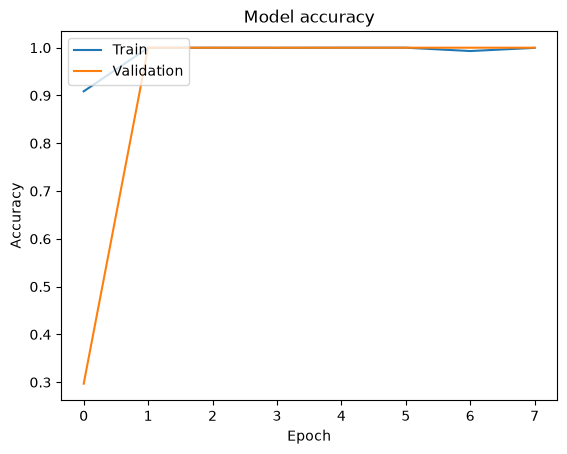

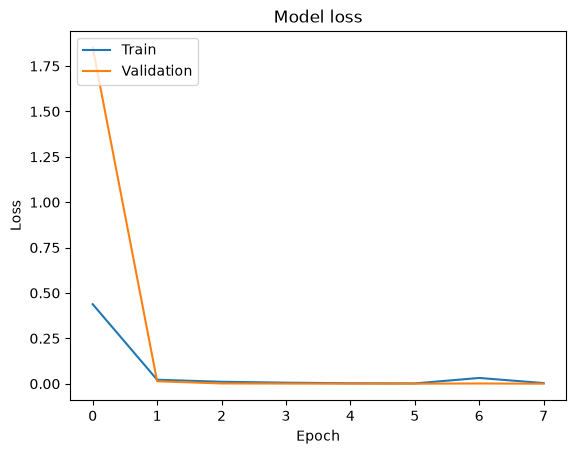

In [51]:
# Plot training & validation accuracy values
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [59]:
model_filename = "kazim_handspell_mnist_custom_cnn.keras"
model.save("../models/" + model_filename)

In [53]:
test_df = pd.read_csv("../raw_data/sign_mnist_test.csv")

print("Dataset shape: ", test_df.shape)
display(test_df.head())

y_test = test_df['label'].values

X_test = test_df.drop(columns=['label']).values
X_test = X_test.reshape(-1, 28, 28, 1)
X_test = X_test.astype('float32') / 255.0

Dataset shape:  (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,10,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


In [54]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=64, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:" , test_accuracy)

Test loss: 0.2185799777507782
Test accuracy: 0.9368376731872559


In [55]:
y_scores= model.predict(X_test, verbose=1)
y_pred = np.argmax(y_scores, axis=1)

labels = np.sort(np.unique(y_test))
label_names = [chr(int(label) + ord('A')) for label in labels]

225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step


In [56]:
print(classification_report(y_test, y_pred, labels=labels, target_names=label_names, digits=3, zero_division=0))

              precision    recall  f1-score   support

           A      0.985     1.000     0.993       331
           B      0.989     1.000     0.994       432
           C      1.000     1.000     1.000       310
           D      1.000     1.000     1.000       245
           E      0.998     0.984     0.991       498
           F      1.000     1.000     1.000       247
           G      0.852     0.940     0.893       348
           H      1.000     0.901     0.948       436
           I      1.000     0.858     0.923       288
           K      0.880     0.888     0.884       331
           L      1.000     1.000     1.000       209
           M      0.944     0.901     0.922       394
           N      0.971     0.928     0.949       291
           O      0.950     1.000     0.974       246
           P      1.000     0.885     0.939       347
           Q      0.804     1.000     0.891       164
           R      0.624     0.854     0.721       144
           S      0.882    

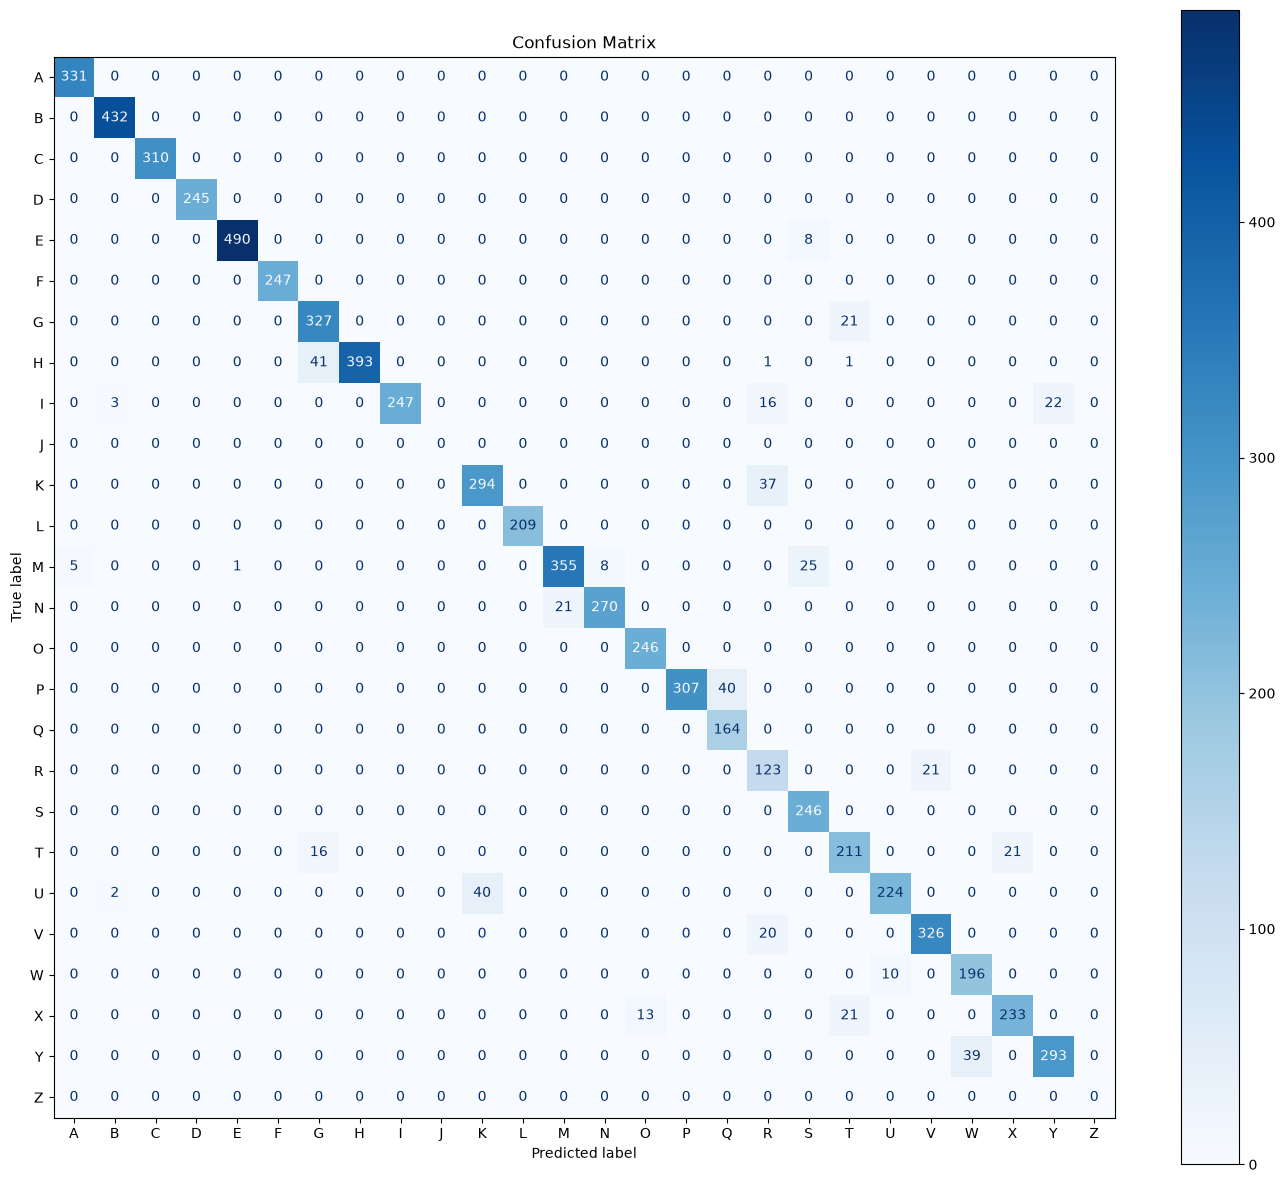

In [57]:
all_labels = np.arange(26)
all_letters = [chr(i + ord('A')) for i in all_labels]

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=all_labels, display_labels=all_letters, cmap='Blues', values_format='d', ax=ax
    )

ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

In [58]:
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.2%}")

macro_f1_with_labels = f1_score(y_test, y_pred, labels=labels, average='macro', zero_division=0)
print(f"Macro F1 Score: {macro_f1_with_labels:.3f}")

Test Accuracy: 93.68%
Macro F1 Score: 0.930
